# Carregamento e prepração dos dados

In [70]:
# Importando pacotes

# Pacote para trazer os dados da AER e econometria
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Pacote para manipulação de dataframes
import pandas as pd

# Pacote para visualização de graficos
import matplotlib.pyplot as plt

In [71]:
# Carregando base de dados
data_r = sm.datasets.get_rdataset("CASchools", "AER")

# Transformando em um DataFrame Pandas
df = data_r.data


## Visualização inicial dos dados

In [73]:
# Visualizazando nome das colunas
df.columns

Index(['district', 'school', 'county', 'grades', 'students', 'teachers',
       'calworks', 'lunch', 'computer', 'expenditure', 'income', 'english',
       'read', 'math'],
      dtype='str')

In [74]:
# Visualizando 2 primeiras linhas
df.head(2)

,district,school,county,grades,students,teachers,calworks,lunch,computer,expenditure,income,english,read,math
0,75119,Sunol Glen Unified,Alameda,KK-08,195,10.90,0.5102,2.040800,67,6384.911133,22.690001,0.000000,691.599976,690.000000
1,61499,Manzanita Elementary,Butte,KK-08,240,11.15,15.4167,47.916698,101,5099.380859,9.824000,4.583333,660.500000,661.900024


## Criando a coluna com a razão de aluno-professor (STR) e media das notas (score)

In [75]:
#STR
df["STR"] = df["students"] / df["teachers"]
df["score"] = ( df["read"] + df["math"] ) /2

# Estatisticas descritivas

## Media amostral, desvio padrão e percentis de STR e score

In [76]:
# Media amostral
media_STR = df["STR"].mean()
media_score = df["score"].mean()

# Desvio-padrão
dp_STR = df["STR"].std()
dp_score = df["score"].std()

# Percentis
percentis = [0.10, 0.25, 0.40, 0.50, 0.60, 0.75, 0.90]

# Quantis
quantis_STR = df["STR"].quantile(percentis)
quantis_score = df["score"].quantile(percentis)


In [79]:
resumo = {
"STR": [
    media_STR,
    dp_STR,
    *quantis_STR
],
"score": [
    media_score,
    dp_score,
    *quantis_score
]

}

df_resumo = pd.DataFrame(
    resumo,
    index = ["Media", "Desvio-Padrão", "10%","25%","40%","50%","60%","75%","90%"])

In [80]:
df_resumo

,STR,score
Media,19.640425,654.156548
Desvio-Padrão,1.891812,19.053347
10%,17.348596,630.395023
25%,18.582360,640.050003
40%,19.266177,649.069989
50%,19.723209,654.449997
60%,20.078303,659.399994
75%,20.871814,666.662491
90%,21.867405,678.859988


# Dispersão

## Grafico de dispersão

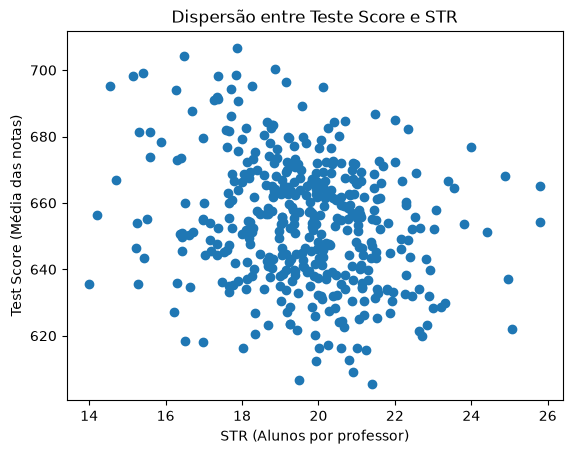

In [81]:
plt.scatter(df.STR, df.score)


plt.xlabel("STR (Alunos por professor)")
plt.ylabel("Test Score (Média das notas)")
plt.title("Dispersão entre Teste Score e STR")

plt.show()

## Correlação entre STR e score

In [82]:
df.STR.corr(df.score)

np.float64(-0.22636274550325575)

# Regressão linear

In [84]:
modelo_linear = smf.ols("score ~ STR", data = df).fit()


In [85]:
# Tabela de regressão
modelo_linear.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  score   R-squared:                       0.051
Model:                            OLS   Adj. R-squared:                  0.049
Method:                 Least Squares   F-statistic:                     22.58
Date:                Thu, 17 Sep 2026   Prob (F-statistic):           2.78e-06
Time:                        13:58:37   Log-Likelihood:                -1822.2
No. Observations:                 420   AIC:                             3648.
Df Residuals:                     418   BIC:                             3657.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    698.9329      9.467     73.825      0.000     680.323     717.543
STR           -2.2798      0.480     -4.751      0.000      -3.223      -1.337
==============================================================================
Omnibus:                        5.390   Durbin-Watson:                   0.129
Prob(Omnibus):                  0.068   Jarque-Bera (JB):                3.589
Skew:                          -0.012   Prob(JB):                        0.166
Kurtosis:                       2.548   Cond. No.                         207.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

# Gráfico da regressão

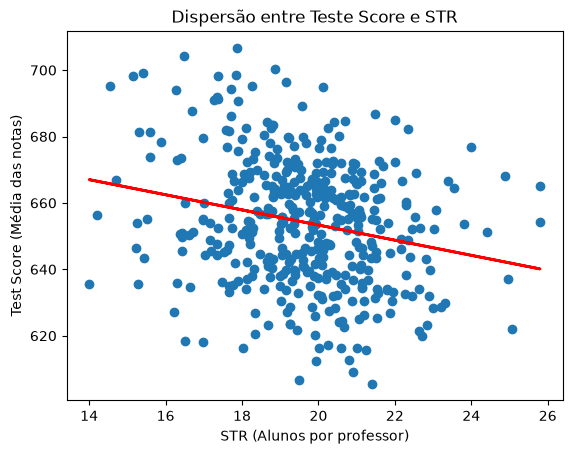

In [88]:
# Gráfico de dispersão scoreXSTR
plt.scatter(df.STR, df.score)

# linha da regressão
plt.plot(
df.STR, # Eixo X
modelo_linear.predict(df), # Eixo Y, (valores estimados de score),
color = "red",
linewidth = 2,
label = "Reta regressão"
)

plt.xlabel("STR (Alunos por professor)")
plt.ylabel("Test Score (Média das notas)")
plt.title("Dispersão entre Teste Score e STR")

plt.show()